# 03 – Tuning and Blending: Chasing the Last Few Thousandths

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 First model](02_first_model.ipynb) · [03 Tuning and blending](03_tuning_and_blending.ipynb) · [04 Calibration](04_calibration.ipynb) · [05 Explanation and fairness](05_explanation_and_fairness.ipynb)

Our first model scored **0.86752** on Kaggle's private leaderboard; the competition's winners reached about **0.87**. So there is very little room left. In this notebook we try the standard tools for squeezing out the last bit of accuracy and, just as importantly, check whether the tiny gains are real.

**Contents**
1. Setup and the starting point
2. How much room is there?
3. Tuning gradient boosting
4. A second boosting library: XGBoost
5. Blending
6. Are the gains real? A fold‑by‑fold check
7. Second Kaggle submission
8. Conclusions

## 1. Setup and the starting point

In [1]:
import sys
sys.path.append("..")   # the project folder, where src/ lives

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

from src.features import CreditFeatures, TARGET, load, log_positive

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")

df = load("../data/cs-training.csv")
test_raw = load("../data/cs-test.csv")
y = df[TARGET].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # same folds as notebook 02

risk_scores = {}


def cv_scores(name, model):
    risk_scores[name] = cross_val_predict(model, df, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    print(f"{name:<36} ROC AUC {roc_auc_score(y, risk_scores[name]):.4f}")


cv_scores("Gradient boosting, default (v1)", make_pipeline(CreditFeatures(), HistGradientBoostingClassifier(random_state=42)))

Gradient boosting, default (v1)      ROC AUC 0.8644


## 2. How much room is there?

Before tuning, it helps to know how much a "better" score can even mean. Here is the same model's AUC in each of the five folds:

In [2]:
fold_scores = [roc_auc_score(y[valid], risk_scores["Gradient boosting, default (v1)"][valid])
               for _, valid in cv.split(df, y)]
print("AUC per fold:", [round(s, 4) for s in fold_scores])
print(f"Spread between folds: {max(fold_scores) - min(fold_scores):.4f}")

AUC per fold: [0.8639, 0.8626, 0.8685, 0.859, 0.8686]
Spread between folds: 0.0095


The **same model** scores between about 0.859 and 0.869 depending only on which borrowers land in the validation fold: a spread of about 0.01. The gap to the competition winners is only about 0.003. So any improvement we find will be **smaller than the normal ups and downs between folds**, and we will need a careful check (section 6) to tell a real gain from luck.

## 3. Tuning gradient boosting

`HistGradientBoostingClassifier` has the same main settings as the boosting models in the house price project, with slightly different names:

| Setting | Meaning |
|---|---|
| `learning_rate`, `max_iter` | how much each tree corrects, and how many trees |
| `max_leaf_nodes` | size of each tree (instead of `max_depth`) |
| `min_samples_leaf` | minimum number of borrowers in a leaf |
| `l2_regularization` | a brake on extreme leaf values, like the `alpha` of Ridge |

We let `RandomizedSearchCV` try 20 combinations. Thanks to the fast histogram method, the whole search takes well under a minute.

In [3]:
%%time
step = "histgradientboostingclassifier__"
hgb_search = RandomizedSearchCV(
    make_pipeline(CreditFeatures(), HistGradientBoostingClassifier(random_state=42)),
    {step + "learning_rate": [0.02, 0.03, 0.05, 0.08], step + "max_iter": [200, 400, 800],
     step + "max_leaf_nodes": [7, 15, 31], step + "min_samples_leaf": [20, 100, 300],
     step + "l2_regularization": [0, 1, 10]},
    n_iter=20, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=42,
).fit(df, y)

print("Best settings:", {k.replace(step, ""): v for k, v in hgb_search.best_params_.items()})
cv_scores("Gradient boosting, tuned", hgb_search.best_estimator_)

Best settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 800, 'learning_rate': 0.02, 'l2_regularization': 1}
Gradient boosting, tuned             ROC AUC 0.8655
CPU times: user 11.6 s, sys: 3.09 s, total: 14.7 s
Wall time: 39 s


Tuning gains about **0.001**. The best settings again follow the rule of thumb from the house price project: a small learning rate (0.02) with many trees (800).

## 4. A second boosting library: XGBoost

**XGBoost** is one of the most widely used libraries in practice and in competitions. It is gradient boosting too, but implemented differently: it grows trees by depth, has its own regularisation, and samples rows and columns for each tree (`subsample`, `colsample_bytree`). Two good implementations of the same idea often make slightly different mistakes, which matters for blending in the next section.

XGBoost also handles missing values by itself, so the same `CreditFeatures` cleaning works unchanged.

In [4]:
%%time
step = "xgbclassifier__"
xgb_search = RandomizedSearchCV(
    make_pipeline(CreditFeatures(), XGBClassifier(eval_metric="auc", tree_method="hist", n_jobs=1, random_state=42)),
    {step + "learning_rate": [0.02, 0.03, 0.05], step + "n_estimators": [300, 600, 1000],
     step + "max_depth": [3, 4, 5], step + "min_child_weight": [1, 5, 20],
     step + "subsample": [0.7, 0.8, 1.0], step + "colsample_bytree": [0.6, 0.8, 1.0]},
    n_iter=15, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=42,
).fit(df, y)

print("Best settings:", {k.replace(step, ""): v for k, v in xgb_search.best_params_.items()})
cv_scores("XGBoost, tuned", xgb_search.best_estimator_)

Best settings: {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
XGBoost, tuned                       ROC AUC 0.8664
CPU times: user 3.43 s, sys: 2.08 s, total: 5.51 s
Wall time: 34.7 s


XGBoost is slightly better again, about **0.002** above the starting point.

## 5. Blending

In the house price project, blending a linear model with a tree model gave the biggest gain. Let's try the same here, with the cleaned logistic regression from notebook 02, and also a blend of the two boosting models.

We average **probabilities**. AUC only cares about the ranking of borrowers, so a weighted average of two sensible risk scores is a sensible risk score too.

Logistic regression, cleaned + log   ROC AUC 0.8549


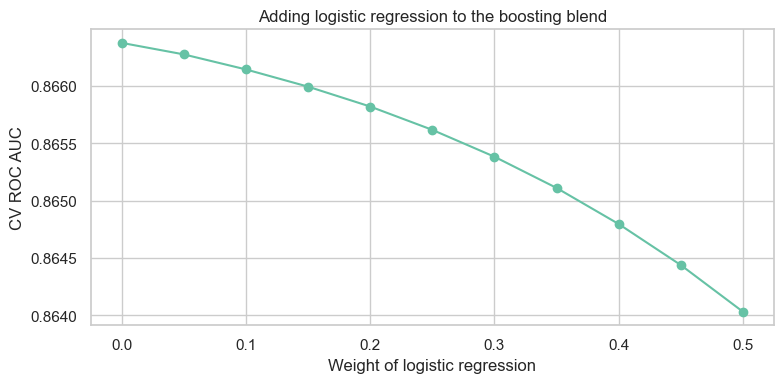

Blend of the two boosting models: ROC AUC 0.8664
CPU times: user 1.02 s, sys: 676 ms, total: 1.7 s
Wall time: 836 ms


In [5]:
%%time
cv_scores("Logistic regression, cleaned + log", make_pipeline(
    CreditFeatures(), SimpleImputer(strategy="median"), FunctionTransformer(log_positive),
    StandardScaler(), LogisticRegression(max_iter=2000)))

boosting_blend = (risk_scores["Gradient boosting, tuned"] + risk_scores["XGBoost, tuned"]) / 2
risk_scores["Blend: gradient boosting + XGBoost"] = boosting_blend

weights = np.round(np.arange(0, 0.51, 0.05), 2)
with_logistic = pd.Series([roc_auc_score(y, (1 - w) * boosting_blend + w * risk_scores["Logistic regression, cleaned + log"])
                           for w in weights], index=weights)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(with_logistic.index, with_logistic.values, marker="o")
ax.set(title="Adding logistic regression to the boosting blend", xlabel="Weight of logistic regression", ylabel="CV ROC AUC")
plt.tight_layout()
plt.show()

print(f"Blend of the two boosting models: ROC AUC {roc_auc_score(y, boosting_blend):.4f}")

Two results, one of them a surprise after the house price project:

- **Adding logistic regression makes things worse.** Every bit of weight given to it lowers the AUC. Blending only helps when the second model is nearly as good *and* makes different mistakes. Logistic regression (0.855) is too far behind here, and on this data the two boosting models already capture everything it knows.
- **Blending the two boosting models** gives about the same score as XGBoost alone (0.8664). It does not raise the average, but, as the next section shows, it makes the result a little more stable.

**Lesson:** blending is not magic. It worked in the house price project because Lasso and gradient boosting were equally good and saw the data differently. Always measure, never assume.

## 6. Are the gains real? A fold‑by‑fold check

The improvements are about 0.002, much smaller than the 0.01 spread between folds. But all models were evaluated on **the same five folds**, so we can compare them **fold by fold**: if a model is really better, it should win in (almost) every fold, not just on average.

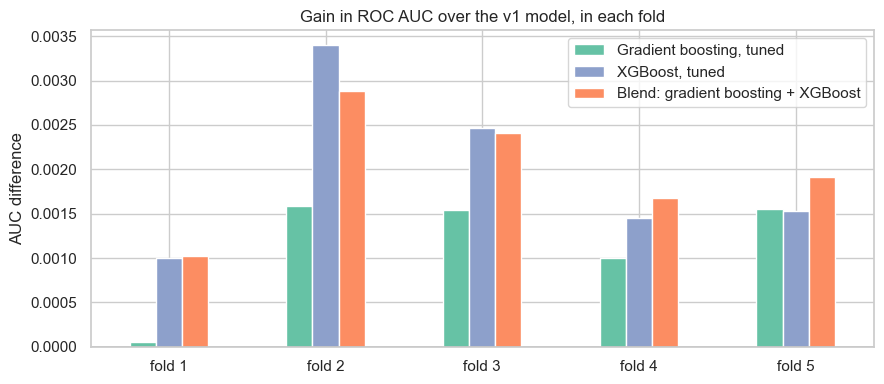

,mean gain,folds with a gain,smallest gain
"Gradient boosting, tuned",0.0011,5,0.000
"XGBoost, tuned",0.0020,5,0.001
Blend: gradient boosting + XGBoost,0.0020,5,0.001


In [6]:
models_to_compare = ["Gradient boosting, default (v1)", "Gradient boosting, tuned", "XGBoost, tuned",
                     "Blend: gradient boosting + XGBoost"]
per_fold = pd.DataFrame({
    name: [roc_auc_score(y[valid], risk_scores[name][valid]) for _, valid in cv.split(df, y)]
    for name in models_to_compare
}, index=[f"fold {i + 1}" for i in range(5)])

gain = per_fold.sub(per_fold["Gradient boosting, default (v1)"], axis=0).drop(columns="Gradient boosting, default (v1)")

fig, ax = plt.subplots(figsize=(9, 4))
gain.plot.bar(ax=ax, color=["C0", "C2", "C1"])
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Gain in ROC AUC over the v1 model, in each fold", ylabel="AUC difference", xlabel="")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../images/gain_per_fold.png", dpi=120)
plt.show()

summary = pd.DataFrame({"mean gain": gain.mean(), "folds with a gain": (gain > 0).sum(), "smallest gain": gain.min()})
summary.round(4)

This is the key result of the notebook. The gains are tiny, but they are **consistent**:

- **XGBoost** and the **blend** are at least as good as the v1 model in **every one of the five folds**.
- The **blend** has the most even gains: it never does worse than v1, and its smallest gain is at least as large as XGBoost's.

When every fold agrees, even a gain of 0.002 is unlikely to be luck. This **paired comparison** is a simple, powerful tool: comparing models on the *same* folds removes the noise that comes from which borrowers happen to be in each fold.

We use the blend for the second submission: it is never worse than v1, and averaging two different implementations makes it less dependent on the quirks of either one.

## 7. Second Kaggle submission

In [7]:
hgb_model = hgb_search.best_estimator_            # RandomizedSearchCV has already refitted both on all borrowers
xgb_model = xgb_search.best_estimator_

blend_test = (hgb_model.predict_proba(test_raw)[:, 1] + xgb_model.predict_proba(test_raw)[:, 1]) / 2
submission = pd.DataFrame({"Id": test_raw["Id"], "Probability": blend_test})
submission.to_csv("../submissions/submission_v2_blend.csv", index=False)

v1 = pd.read_csv("../submissions/submission_v1_boosting.csv")
print(f"Saved {len(submission):,} predictions to submissions/submission_v2_blend.csv")
print(f"Correlation of the risk ranking with v1: {submission['Probability'].corr(v1['Probability'], method='spearman'):.3f}")

Saved 101,503 predictions to submissions/submission_v2_blend.csv
Correlation of the risk ranking with v1: 0.989


The new ranking of applicants is very similar to v1 (the correlation is close to 1), as expected from a gain of 0.002.

Upload `submissions/submission_v2_blend.csv` as a **Late Submission** on the [competition page](https://www.kaggle.com/c/GiveMeSomeCredit/submit).

| Submission | Model | CV ROC AUC | Kaggle public | Kaggle private |
|---|---|---|---|---|
| v1 | Gradient boosting, default settings | 0.8644 | 0.86024 | 0.86752 |
| v2 | Blend of tuned gradient boosting and XGBoost | 0.8664 | _fill in_ | _fill in_ |

**What to expect:** an improvement of about 0.002 on Kaggle too, perhaps from 0.8675 to about 0.869 on the private score. Because the public score uses fewer applicants, it may move more or less than that.

## 8. Conclusions

| Model | CV ROC AUC |
|---|---|
| Gradient boosting, default (v1) | 0.8644 |
| Gradient boosting, tuned | 0.8655 |
| XGBoost, tuned | 0.8664 |
| **Blend of both** | **0.8664** |

**What we learned**

| Concept | In one sentence |
|---|---|
| **Diminishing returns** | Close to the limit of what the data allows, tuning and blending add thousandths, not hundredths. |
| **XGBoost** | A widely used gradient boosting library; slightly better than scikit‑learn's here. |
| **When blending helps** | Only when the models are nearly equally good and make different mistakes. |
| **Paired fold‑by‑fold comparison** | Comparing models on the same folds shows whether a tiny gain is consistent or luck. |

**The honest conclusion:** the first model was already close to the best possible. In a real bank, the effort in this notebook would probably not be worth it. Better *data* (for example the borrower's full payment history) would help far more than better tuning. The next two notebooks look at questions that matter more in practice: can we trust the risk scores as probabilities, and is the model fair?